In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import certifi
import requests
from io import BytesIO
from plotly import express as px
from pyjstat import pyjstat
import matplotlib.dates as mdates

Benytter hovedsakelig tabell 11561 fra ssb.no til dette scriptet. Lenke: https://www.ssb.no/statbank/table/11561

In [2]:
get_url = "https://data.ssb.no/api/pxwebapi/v2/tables/11561/data?lang=no&outputFormat=json-stat2&valuecodes[ContentsCode]=EnergibalansenGWh&valuecodes[Tid]=*&valuecodes[Energibalanse]=*&codelist[Energibalanse]=vs_Energibalansepost01&valuecodes[EnergiProdukt]=*&codelist[EnergiProdukt]=vs_EnergiProdukt&heading=ContentsCode,Tid,EnergiProdukt&stub=Energibalanse"

response = requests.get(get_url)

if response.status_code == 200:
    dataset = pyjstat.Dataset.read(response.text)
    df = dataset.write("dataframe")
    print(df.head())
else:
    print(f"Feil: {response.status_code}")

                         energibalansepost    statistikkvariabel    år  \
0  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
1  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
2  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
3  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
4  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   

                        energiprodukt      value  
0                Alle energiprodukter  1376707.0  
1               Kull og kullprodukter     2364.0  
2                           Naturgass   275913.0  
3  Olje og oljeprodukter (ekskl. bio)   966406.0  
4                         Biobrensler     9442.0  


In [3]:
oljeindustri_forbruk = df[df.energibalansepost == '8 Eget forbruk i energiproduserende sektor']

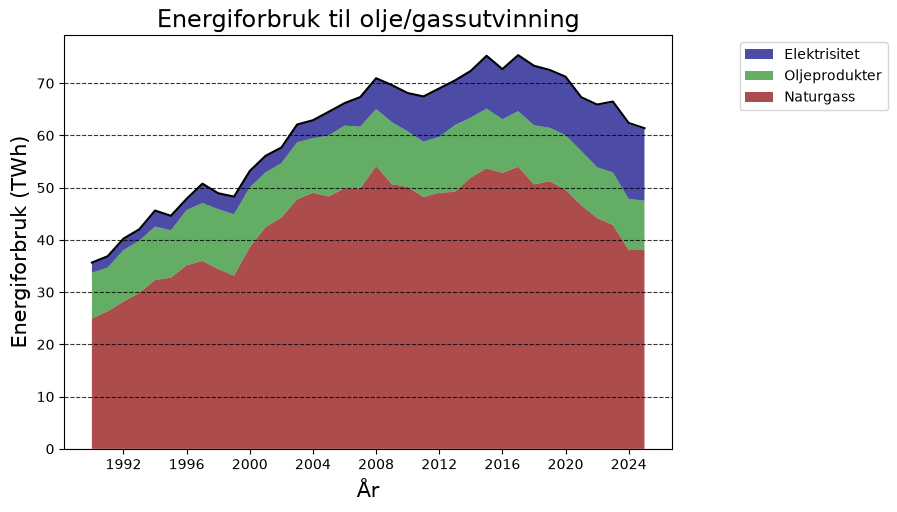

In [4]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    oljeindustri_forbruk['år'].unique().astype(int),
    oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Naturgass', 'value'] / 1e3,
    oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Olje og oljeprodukter (ekskl. bio)', 'value'] / 1e3,
    oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Elektrisitet', 'value'] / 1e3,
    labels=['Naturgass', 'Oljeprodukter', 'Elektrisitet'],
    colors=['darkred', 'forestgreen', 'navy'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(oljeindustri_forbruk['år'].unique().astype(int), 
        oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Alle energiprodukter', 'value'] / 1e3, 
        color = 'black')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Energiforbruk til olje/gassutvinning', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

# Produksjon fossile brensler

In [5]:
fossil_prod = df[df.energibalansepost == '1 Produksjon av primære energiprodukter']

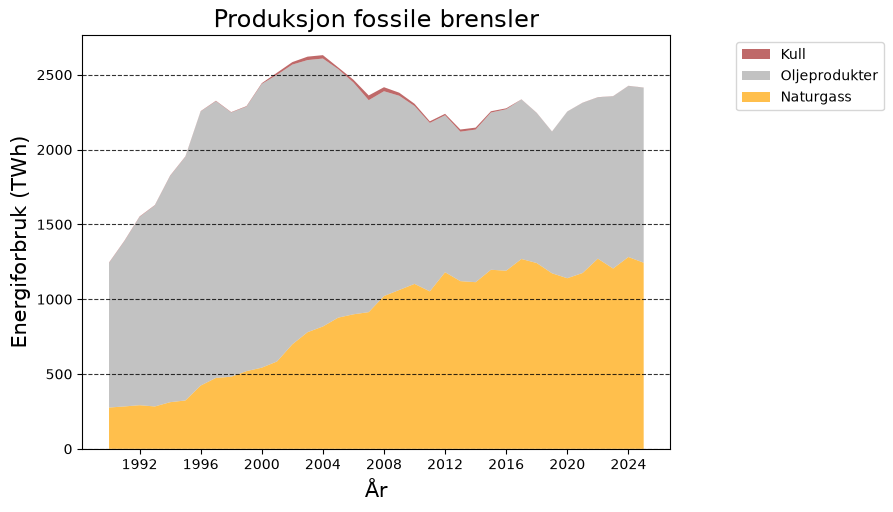

In [6]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    fossil_prod['år'].unique().astype(int),
    fossil_prod.loc[fossil_prod.energiprodukt == 'Naturgass', 'value'] / 1e3,
    fossil_prod.loc[fossil_prod.energiprodukt == 'Olje og oljeprodukter (ekskl. bio)', 'value'] / 1e3,
    fossil_prod.loc[fossil_prod.energiprodukt == 'Kull og kullprodukter', 'value'] / 1e3,
    labels=['Naturgass', 'Oljeprodukter', 'Kull'],
    colors=['orange', 'darkgrey', 'brown'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Produksjon fossile brensler', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

# Elektrisitet produksjon og forbruk

In [7]:
elektrisitet = df[df.energiprodukt == 'Elektrisitet']

In [8]:
innenlandsbruk = elektrisitet.loc[elektrisitet.energibalansepost == '6 Netto innenlands tilgang (1+2-3-4+5)','value'].to_numpy()
netto_eksport = elektrisitet.loc[elektrisitet.energibalansepost == '3 Eksport', 'value'].to_numpy() - elektrisitet.loc[elektrisitet.energibalansepost == '2 Import', 'value'].to_numpy()

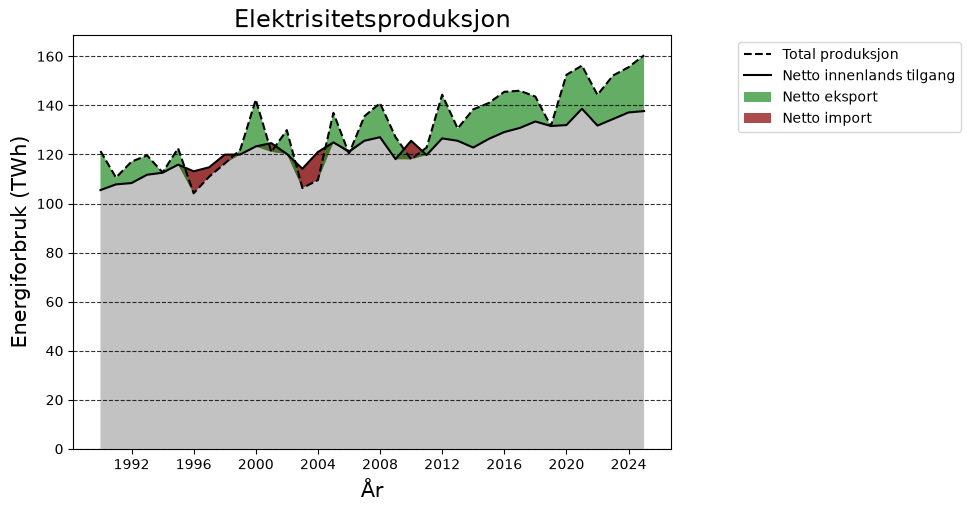

In [9]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    elektrisitet['år'].unique().astype(int),
    innenlandsbruk / 1e3,
    np.clip(netto_eksport, None , 0) / 1e3,
    np.clip(netto_eksport, 0 , None) / 1e3,
    labels=['', 'Netto import', 'Netto eksport'],
    colors=['darkgrey', 'darkred', 'forestgreen'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(elektrisitet['år'].unique().astype(int), 
        elektrisitet.loc[elektrisitet.energibalansepost == '6 Netto innenlands tilgang (1+2-3-4+5)', 'value'] / 1e3,
        color = 'black',
        label = 'Netto innenlands tilgang')

ax.plot(elektrisitet['år'].unique().astype(int), 
        elektrisitet.loc[elektrisitet.energibalansepost == '1 Produksjon av primære energiprodukter', 'value'] / 1e3,
        color = 'black', linestyle= '--',
        label = 'Total produksjon')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Elektrisitetsproduksjon', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

## Innenlands forbruk

In [41]:
andre = elektrisitet.loc[elektrisitet.energibalansepost == '12.3 Andre forbruksgrupper', 'value'].to_numpy()
industri = elektrisitet.loc[elektrisitet.energibalansepost == '12.1 Industri og bergverk', 'value'].to_numpy()
transport = elektrisitet.loc[elektrisitet.energibalansepost == '12.2 Transport', 'value'].to_numpy()
oljeproduksjon = elektrisitet.loc[elektrisitet.energibalansepost == '8 Eget forbruk i energiproduserende sektor', 'value'].to_numpy()
svinn = elektrisitet.loc[elektrisitet.energibalansepost == '7 Transformasjon', 'value'].to_numpy() + elektrisitet.loc[elektrisitet.energibalansepost == '9 Svinn', 'value'].to_numpy() + elektrisitet.loc[elektrisitet.energibalansepost == '13 Statistiske feil (6+7-8-9-10)', 'value'].to_numpy()

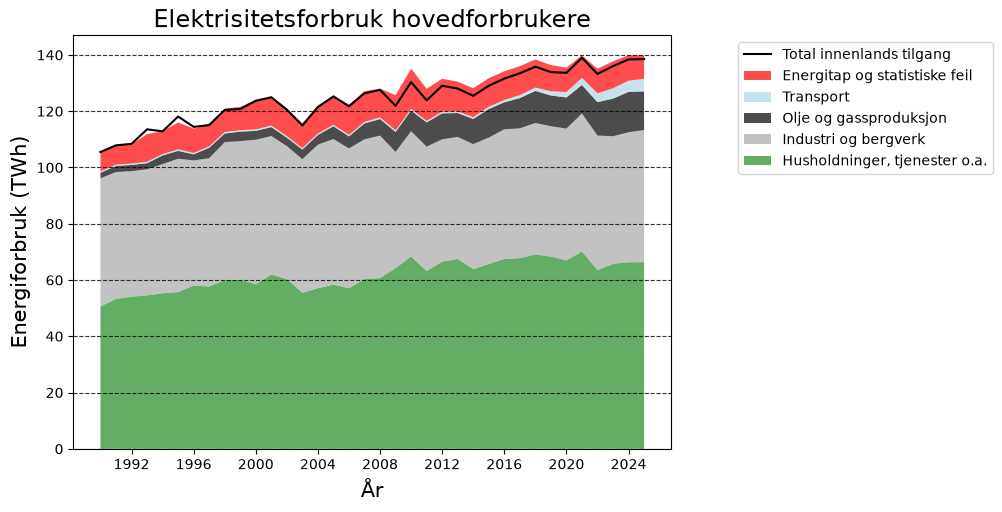

In [43]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    elektrisitet['år'].unique().astype(int),
    andre / 1e3,
    industri / 1e3,
    oljeproduksjon / 1e3,
    transport / 1e3,
    svinn / 1e3,
    labels=['Husholdninger, tjenester o.a.', 'Industri og bergverk', 'Olje og gassproduksjon', 'Transport', 'Energitap og statistiske feil'],
    colors=['forestgreen', 'darkgrey', 'black', 'lightblue', 'red'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(elektrisitet['år'].unique().astype(int), 
        (elektrisitet.loc[elektrisitet.energibalansepost == '6 Netto innenlands tilgang (1+2-3-4+5)', 'value'] 
        + elektrisitet.loc[elektrisitet.energibalansepost == '7 Transformasjon', 'value'].to_numpy()
        + elektrisitet.loc[elektrisitet.energibalansepost == '13 Statistiske feil (6+7-8-9-10)', 'value'].to_numpy()) / 1e3,
        color = 'black', label = 'Total innenlands tilgang')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Elektrisitetsforbruk hovedforbrukere', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

**More detailed dataset**

Lenke for å se tabellen på ssb: https://www.ssb.no/statbank/table/11561

Lenke til klassifisering: https://dataportal.ssb.no/classifications/157/codes

In [12]:
# Mer detaljert tabell

get_url = "https://data.ssb.no/api/pxwebapi/v2/tables/11561/data?lang=no&outputFormat=json-stat2&valuecodes[ContentsCode]=EnergibalansenGWh&valuecodes[Tid]=*&valuecodes[Energibalanse]=*&codelist[Energibalanse]=vs_Energibalansepost02&valuecodes[EnergiProdukt]=*&codelist[EnergiProdukt]=vs_EnergiProdukt&heading=ContentsCode,Tid&stub=Energibalanse,EnergiProdukt"

response = requests.get(get_url)

if response.status_code == 200:
    dataset = pyjstat.Dataset.read(response.text)
    df = dataset.write("dataframe")
    print(df.head())
else:
    print(f"Feil: {response.status_code}")

                         energibalansepost         energiprodukt  \
0  1 Produksjon av primære energiprodukter  Alle energiprodukter   
1  1 Produksjon av primære energiprodukter  Alle energiprodukter   
2  1 Produksjon av primære energiprodukter  Alle energiprodukter   
3  1 Produksjon av primære energiprodukter  Alle energiprodukter   
4  1 Produksjon av primære energiprodukter  Alle energiprodukter   

     statistikkvariabel    år      value  
0  Energibalansen (GWh)  1990  1376707.0  
1  Energibalansen (GWh)  1991  1510138.0  
2  Energibalansen (GWh)  1992  1679697.0  
3  Energibalansen (GWh)  1993  1759704.0  
4  Energibalansen (GWh)  1994  1950570.0  


In [13]:
elektrisitet = df[df.energiprodukt == 'Elektrisitet']

### Industri

In [14]:
industri_total = elektrisitet.loc[elektrisitet.energibalansepost == '12.1 Industri og bergverk', 'value'].to_numpy()
jern = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.1 Produksjon av jern,stål, og ferrolegeringer', 'value'].to_numpy()
kjemisk = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.2 Produksjon av kjemiske og farmasøytiske produkter', 'value'].to_numpy()
metall = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.3 Produksjon av ikke-jernholdige metaller', 'value'].to_numpy()
mineral = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.4 Produksjon av ikke metallholdige mineralprodukter', 'value'].to_numpy()
transportmidler = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.5 Produksjon av motorvogner, tilhengere og andre transportmidler', 'value'].to_numpy()
maskiner = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.6 Produksjon av metallvarer, maskiner og utstyr', 'value'].to_numpy()
bergverk = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.7 Bergverk', 'value'].to_numpy()
næringsmidler = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.8 Produksjon av nærings- og nytelsesmidler', 'value'].to_numpy()
papir = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.9 Produksjon av papir og papirvarer, og trykking', 'value'].to_numpy()
treforedling = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.10 Treforedling', 'value'].to_numpy()
tekstiler = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.11 Produksjon av tekstiler, klær, lær og lærvarer', 'value'].to_numpy()
bygg = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.12 Bygg og anlegg', 'value'].to_numpy()
annet = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.13 Annen industri', 'value'].to_numpy()

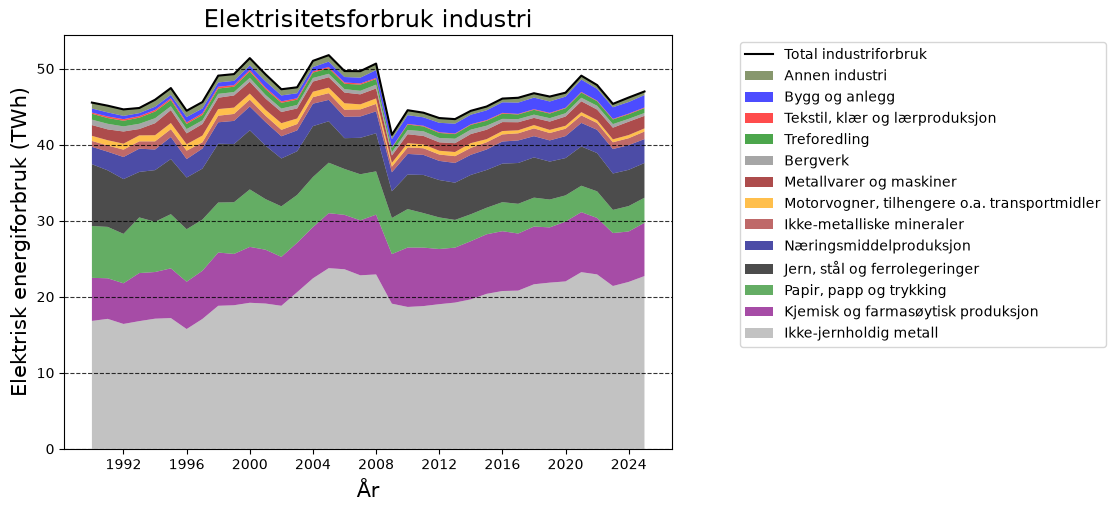

In [15]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Elektrisk energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    elektrisitet['år'].unique().astype(int),
    metall / 1e3,
    kjemisk / 1e3,
    papir / 1e3,
    jern / 1e3,
    næringsmidler / 1e3,
    mineral / 1e3,
    transportmidler / 1e3,
    maskiner / 1e3,
    bergverk / 1e3,
    treforedling / 1e3,
    tekstiler / 1e3,
    bygg / 1e3,
    annet / 1e3,
    labels=['Ikke-jernholdig metall', 'Kjemisk og farmasøytisk produksjon', 'Papir, papp og trykking', 'Jern, stål og ferrolegeringer', 
            'Næringsmiddelproduksjon', 'Ikke-metalliske mineraler', 'Motorvogner, tilhengere o.a. transportmidler', 'Metallvarer og maskiner',
            'Bergverk', 'Treforedling', 'Tekstil, klær og lærproduksjon', 'Bygg og anlegg', 'Annen industri'],
    colors=['darkgrey', 'purple', 'forestgreen', 'black', 'navy', 'brown', 'orange', 'darkred', 'grey', 'green', 'red', 'blue', 'darkolivegreen'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(elektrisitet['år'].unique().astype(int), 
        industri_total / 1e3,
        color = 'black', label = 'Total industriforbruk')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Elektrisitetsforbruk industri', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

### Transport

In [16]:
transport = elektrisitet.loc[elektrisitet.energibalansepost == '12.2 Transport', 'value'].to_numpy()
vei = elektrisitet.loc[elektrisitet.energibalansepost == '12.2.1 Veitransport', 'value'].to_numpy()
bane = elektrisitet.loc[elektrisitet.energibalansepost == '12.2.2 Banetransport', 'value'].to_numpy()
luft = elektrisitet.loc[elektrisitet.energibalansepost == '12.2.3 Lufttransport', 'value'].to_numpy()
kyst = elektrisitet.loc[elektrisitet.energibalansepost == '12.2.4 Kysttransport', 'value'].to_numpy()
annet = elektrisitet.loc[elektrisitet.energibalansepost == '12.2.5 Annen transport', 'value'].to_numpy()

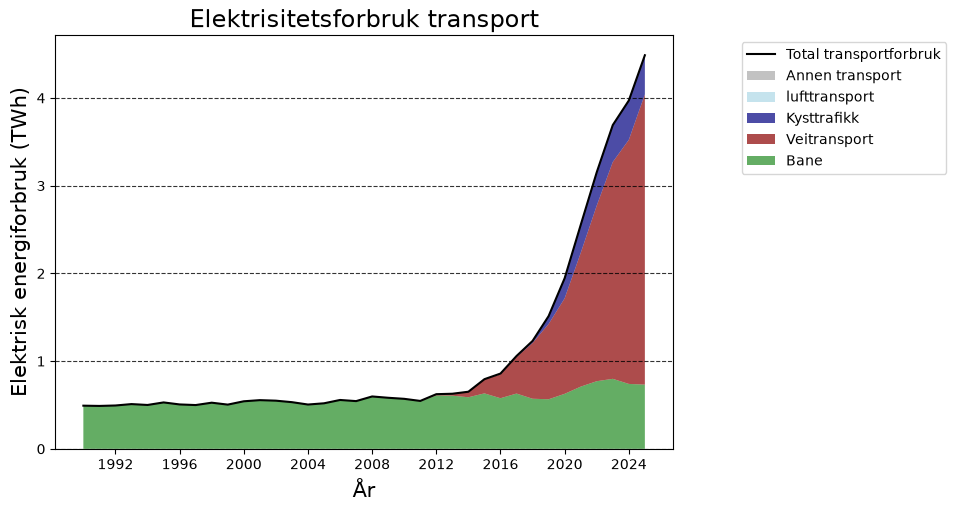

In [17]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Elektrisk energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    elektrisitet['år'].unique().astype(int),
    bane / 1e3,
    vei / 1e3,
    kyst / 1e3,
    luft / 1e3,
    annet / 1e3,
    labels=['Bane', 'Veitransport', 'Kysttrafikk', 'lufttransport', 'Annen transport'],
    colors=['forestgreen', 'darkred', 'navy', 'lightblue', 'darkgray'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(elektrisitet['år'].unique().astype(int), 
        transport / 1e3,
        color = 'black', label = 'Total transportforbruk')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Elektrisitetsforbruk transport', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

### Husholdninger, tjenester og andre forbrukere

In [18]:
andre_forbrukere = elektrisitet.loc[elektrisitet.energibalansepost == '12.3 Andre forbruksgrupper', 'value'].to_numpy()
jordbruk = elektrisitet.loc[elektrisitet.energibalansepost == '12.3.1 Jordbruk og skogbruk', 'value'].to_numpy()
fiske = elektrisitet.loc[elektrisitet.energibalansepost == '12.3.2 Fiske', 'value'].to_numpy()
tjeneste = elektrisitet.loc[elektrisitet.energibalansepost == '12.3.3 Privat og offentlig tjenesteyting, inkl. forsvar', 'value'].to_numpy()
husholdninger = elektrisitet.loc[elektrisitet.energibalansepost == '12.3.4 Private husholdninger', 'value'].to_numpy()

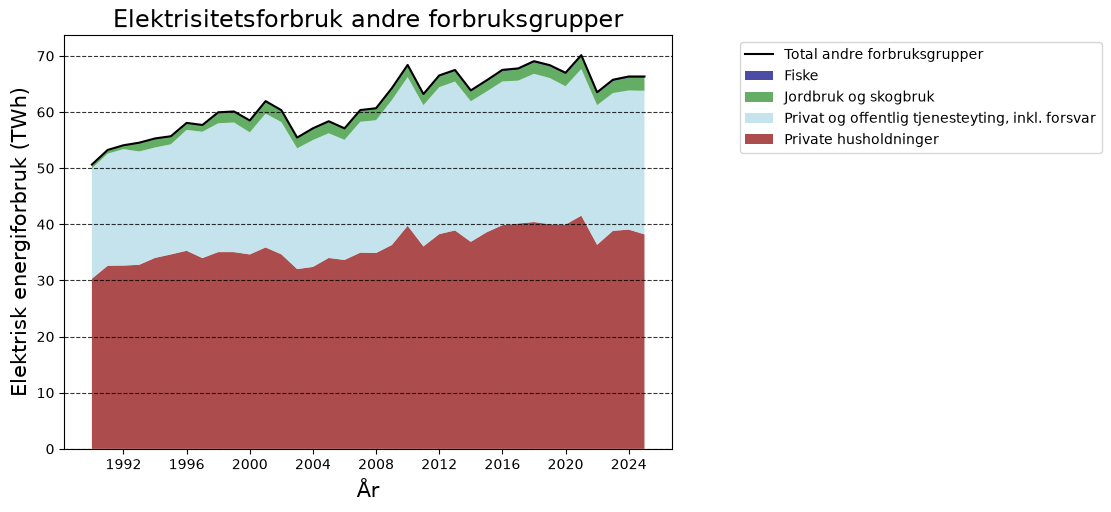

In [19]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Elektrisk energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    elektrisitet['år'].unique().astype(int),
    husholdninger / 1e3,
    tjeneste / 1e3,
    jordbruk / 1e3,
    fiske / 1e3,
    labels=['Private husholdninger', 'Privat og offentlig tjenesteyting, inkl. forsvar', 'Jordbruk og skogbruk', 'Fiske'],
    colors=['darkred', 'lightblue', 'forestgreen', 'navy'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(elektrisitet['år'].unique().astype(int), 
        andre_forbrukere / 1e3,
        color = 'black', label = 'Total andre forbruksgrupper')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Elektrisitetsforbruk andre forbruksgrupper', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

# Oljeforbruk i Norge

In [21]:
olje = df[df.energiprodukt == 'Olje og oljeprodukter (ekskl. bio)']

In [24]:
olje_innenlandsforbruk = olje.loc[olje.energibalansepost == '6 Netto innenlands tilgang (1+2-3-4+5)', 'value'].to_numpy()
råstoff = olje.loc[olje.energibalansepost == '11 Netto innenlands forbruk som råstoff', 'value'].to_numpy()
andre = olje.loc[olje.energibalansepost == '12.3 Andre forbruksgrupper', 'value'].to_numpy()
industri = olje.loc[olje.energibalansepost == '12.1 Industri og bergverk', 'value'].to_numpy()
transport = olje.loc[olje.energibalansepost == '12.2 Transport', 'value'].to_numpy()
oljeproduksjon = olje.loc[olje.energibalansepost == '8 Eget forbruk i energiproduserende sektor', 'value'].to_numpy()
svinn = olje.loc[olje.energibalansepost == '7 Transformasjon', 'value'].to_numpy() + olje.loc[olje.energibalansepost == '9 Svinn', 'value'].to_numpy() + olje.loc[olje.energibalansepost == '13 Statistiske feil (6+7-8-9-10)', 'value'].to_numpy()

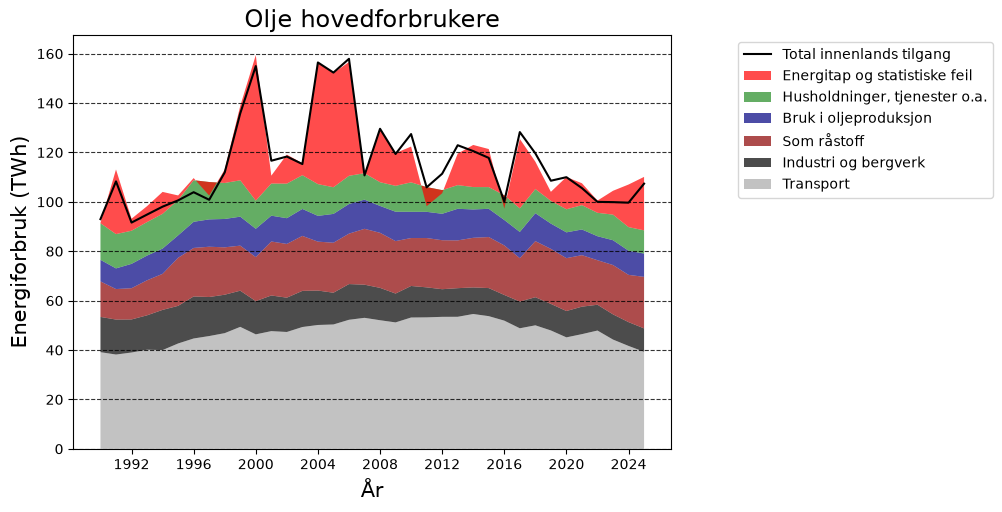

In [23]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    olje['år'].unique().astype(int),
    transport / 1e3,
    industri/ 1e3,
    råstoff / 1e3,
    oljeproduksjon / 1e3,
    andre / 1e3,
    svinn / 1e3,
    labels=['Transport' , 'Industri og bergverk', 'Som råstoff', 'Bruk i oljeproduksjon', 'Husholdninger, tjenester o.a.',
            'Energitap og statistiske feil'],
    colors=['darkgray', 'black', 'darkred', 'navy', 'forestgreen', 'red'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(olje['år'].unique().astype(int), 
        olje_innenlandsforbruk / 1e3,
        color = 'black', label = 'Total innenlands tilgang')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Olje hovedforbrukere', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

**Kommentar**: Bruk i oljeproduksjon kan deles i to, direkte til bruk i olje og gassutvinning og raffinering av olje. Det er noe høyere bruk av olje til raffinering.

**Oljeforbruk 2025**

In [28]:
data = {'Oljeforbruker': ['Transport', 'Industri og bergverk', 'Som råstoff', 'Oljeproduksjon', 'Husholdninger, tjenester o.a.'],
        'Energiforbruk': [transport[-1], industri[-1], råstoff[-1], oljeproduksjon[-1], andre[-1]]}

olje_df = pd.DataFrame(data)

olje_df['Energiforbruk'] = olje_df['Energiforbruk'] / 1e3

In [29]:
color_map = {
    'Transport': "#787878",
    'Industri og bergverk': "#000000",
    'Som råstoff': "#6F1F1F",
    'Oljeproduksjon':  '#0D00FF',
    'Husholdninger, tjenester o.a.': "#3A6B2C",
}

# 3. Lag diagrammet med både names og color satt til den nye kolonnen
fig = px.pie(
    olje_df,
    names='Oljeforbruker',
    color='Oljeforbruker',
    values='Energiforbruk',
    title='2025 norsk oljeforbruk',
    color_discrete_map=color_map,
)

fig.show()

## Transport

Bryter kun ned transport i sine komponenter, da de andre hovedgruppene er ganske små sammenlignet med denne

In [ ]:
transport_totalt = olje.loc[olje.energibalansepost == '12.2 Transport', 'value'].to_numpy()
vei = olje.loc[olje.energibalansepost == '12.2.1 Veitransport', 'value'].to_numpy()
kyst = olje.loc[olje.energibalansepost == '12.2.4 Kysttransport', 'value'].to_numpy()
bane = olje.loc[olje.energibalansepost == '12.2.2 Banetransport', 'value'].to_numpy()
luft = olje.loc[olje.energibalansepost == '12.2.3 Lufttransport', 'value'].to_numpy()

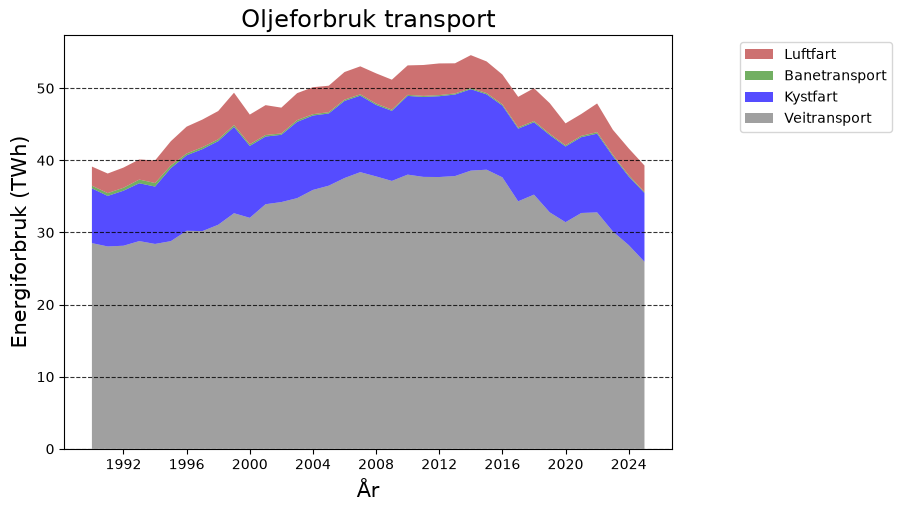

In [39]:
fig, ax = plt.subplots()

color_map = {
    'Veitransport': "#787878",
    'Kystfart':  '#0D00FF',
    'Banetransport': "#378D1F",
    'Luftfart': "#B83535"
}

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    olje['år'].unique().astype(int),
    vei / 1e3,
    kyst / 1e3,
    bane / 1e3,
    luft / 1e3,
    labels=color_map.keys(),
    colors=color_map.values(),
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Oljeforbruk transport', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

# Naturgass

In [45]:
gass = df[df.energiprodukt == 'Naturgass']

In [48]:
gass_innenlandsbruk = gass.loc[gass.energibalansepost == '6 Netto innenlands tilgang (1+2-3-4+5)', 'value'].to_numpy()
råstoff = gass.loc[gass.energibalansepost == '11 Netto innenlands forbruk som råstoff', 'value'].to_numpy()
andre = gass.loc[gass.energibalansepost == '12.3 Andre forbruksgrupper', 'value'].to_numpy()
industri = gass.loc[gass.energibalansepost == '12.1 Industri og bergverk', 'value'].to_numpy()
transport = gass.loc[gass.energibalansepost == '12.2 Transport', 'value'].to_numpy()
oljeproduksjon = gass.loc[gass.energibalansepost == '8 Eget forbruk i energiproduserende sektor', 'value'].to_numpy()
fakling = gass.loc[gass.energibalansepost == 'Memo01: Gass faklet på oljefelter, terminaler og deponier', 'value'].to_numpy() + gass.loc[gass.energibalansepost == 'Memo02: Avlufting/lekkasje av naturgass og råolje på oljefelter', 'value'].to_numpy()
svinn = gass.loc[gass.energibalansepost == '7 Transformasjon', 'value'].to_numpy() + gass.loc[gass.energibalansepost == '9 Svinn', 'value'].to_numpy() + gass.loc[gass.energibalansepost == '13 Statistiske feil (6+7-8-9-10)', 'value'].to_numpy()

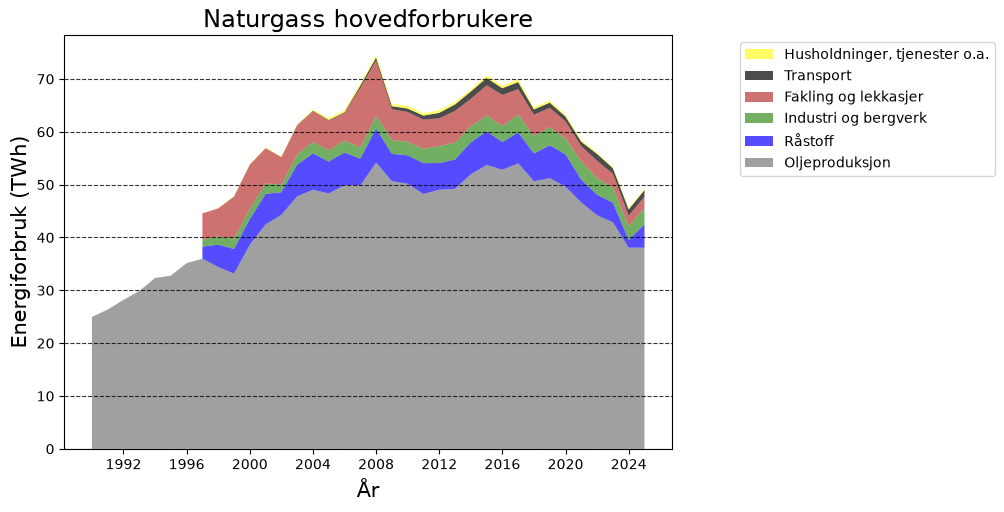

In [ ]:
color_map = {
    'Olje- og gassproduksjon': "#787878",
    'Råstoff':  '#0D00FF',
    'Industri og bergverk': "#378D1F",
    'Fakling og lekkasjer': "#B83535",
    'Transport': "#000000",
    'Husholdninger, tjenester o.a.': "#FEFE22",
    'Energitap, transformasjon og statistiske avvik': "#6E2525",
}

fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    gass['år'].unique().astype(int),
    oljeproduksjon / 1e3,
    råstoff / 1e3,
    industri / 1e3,
    fakling / 1e3,
    transport / 1e3,
    andre / 1e3,
    labels=color_map.keys(),
    colors=color_map.values(),
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Naturgass hovedforbrukere', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')

**Kommentar**: Oljeproduksjon innebærer nærmest utelukkende naturgass brukt direkte til olje og gassutvinning.

# Banetransport

Se på energikildene som brukes til banetransport

In [ ]:
bane = df[df.energibalansepost == '12.2.2 Banetransport']

,energibalansepost,energiprodukt,statistikkvariabel,år,value
16848,12.2.2 Banetransport,Alle energiprodukter,Energibalansen (GWh),1990,865.0
16849,12.2.2 Banetransport,Alle energiprodukter,Energibalansen (GWh),1991,881.0
16850,12.2.2 Banetransport,Alle energiprodukter,Energibalansen (GWh),1992,900.0
16851,12.2.2 Banetransport,Alle energiprodukter,Energibalansen (GWh),1993,1020.0
16852,12.2.2 Banetransport,Alle energiprodukter,Energibalansen (GWh),1994,992.0


In [75]:
bane_el = bane.loc[bane.energiprodukt == 'Elektrisitet', 'value'].to_numpy()
bane_olje = bane.loc[bane.energiprodukt == 'Olje og oljeprodukter (ekskl. bio)', 'value'].to_numpy()
bane_gass = bane.loc[bane.energiprodukt == 'Naturgass', 'value'].to_numpy()
bane_bio = bane.loc[bane.energiprodukt == 'Biobrensler', 'value'].to_numpy()
andre = bane.loc[bane.energiprodukt == 'Andre energiprodukter', 'value'].to_numpy()
kull = bane.loc[bane.energiprodukt == 'Kull og kullprodukter', 'value'].to_numpy()

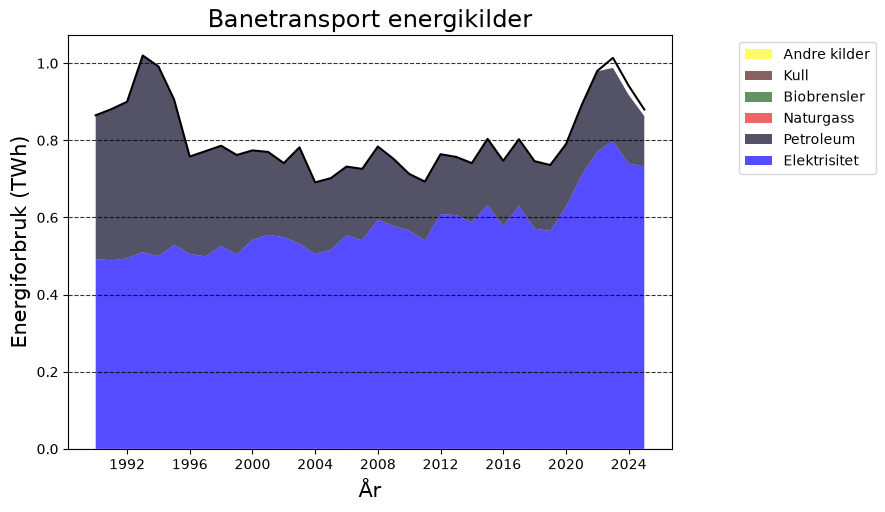

In [ ]:
color_map = {
    'Elektrisitet': '#0D00FF',
    'Petroleum':  "#0A0827",
    'Naturgass': "#E32525",
    'Biobrensler': "#1F641C",
    'Kull': "#562020",
    'Andre kilder': "#FEFE22"
}

fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    bane['år'].unique().astype(int),
    bane_el / 1e3,
    bane_olje / 1e3,
    bane_gass / 1e3,
    bane_bio / 1e3,
    kull / 1e3,
    andre / 1e3,
    labels=color_map.keys(),
    colors=color_map.values(),
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Banetransport energikilder', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')

# Veitransport

En titt på energikildene til veitransporten

In [80]:
vei = df[df.energibalansepost == '12.2.1 Veitransport']

In [81]:
vei_el = vei.loc[vei.energiprodukt == 'Elektrisitet', 'value'].to_numpy()
vei_olje = vei.loc[vei.energiprodukt == 'Olje og oljeprodukter (ekskl. bio)', 'value'].to_numpy()
vei_gass = vei.loc[vei.energiprodukt == 'Naturgass', 'value'].to_numpy()
vei_bio = vei.loc[vei.energiprodukt == 'Biobrensler', 'value'].to_numpy()
andre = vei.loc[vei.energiprodukt == 'Andre energiprodukter', 'value'].to_numpy()
kull = vei.loc[vei.energiprodukt == 'Kull og kullprodukter', 'value'].to_numpy()

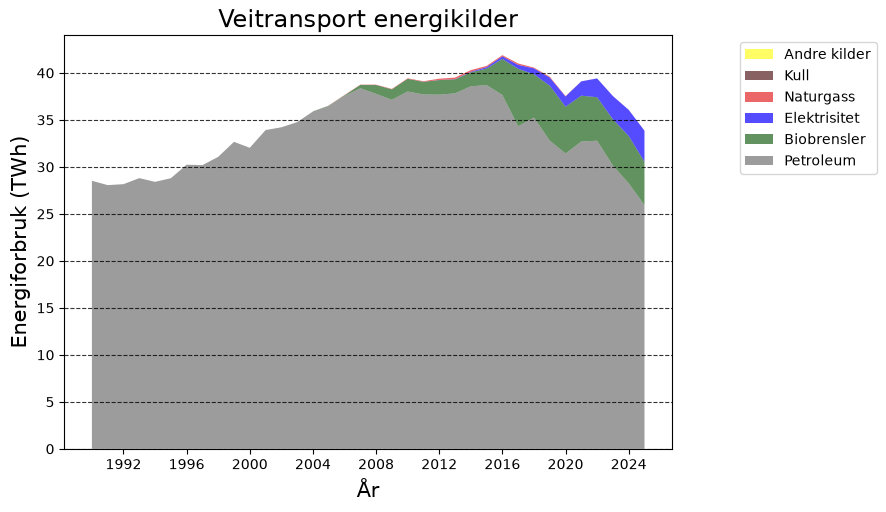

In [86]:
color_map = {
    'Petroleum':  "#727272",
    'Biobrensler': "#1F641C",
    'Elektrisitet': '#0D00FF',
    'Naturgass': "#E32525",
    'Kull': "#562020",
    'Andre kilder': "#FEFE22"
}

fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    vei['år'].unique().astype(int),
    vei_olje / 1e3,
    vei_bio / 1e3,
    vei_el / 1e3,
    vei_gass / 1e3,
    kull / 1e3,
    andre / 1e3,
    labels=color_map.keys(),
    colors=color_map.values(),
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

"""
ax.plot(vei['år'].unique().astype(int),
        vei.loc[vei.energiprodukt == 'Alle energiprodukter', 'value'].to_numpy() / 1e3,
        color = 'black')
"""

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Veitransport energikilder', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')